In [123]:
import pandas as pd
file_name = 'sentimentdataset.csv'
sentiment_data = pd.read_csv(file_name)
sentiment_data.head()

,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


In [124]:
sentiment_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 15 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0.1  732 non-null    int64  
 1   Unnamed: 0    732 non-null    int64  
 2   Text          732 non-null    object 
 3   Sentiment     732 non-null    object 
 4   Timestamp     732 non-null    object 
 5   User          732 non-null    object 
 6   Platform      732 non-null    object 
 7   Hashtags      732 non-null    object 
 8   Retweets      732 non-null    float64
 9   Likes         732 non-null    float64
 10  Country       732 non-null    object 
 11  Year          732 non-null    int64  
 12  Month         732 non-null    int64  
 13  Day           732 non-null    int64  
 14  Hour          732 non-null    int64  
dtypes: float64(2), int64(6), object(7)
memory usage: 85.9+ KB


In [125]:
import random
import numpy as np 
import matplotlib.pyplot as plt

# Define the Hybrid Hypergraph-Nonlinear-Latency Voter Model
class VoterModel:
    def __init__(self, num_nodes, hyperedges, q, latency, consensus_threshold):
        self.num_nodes = num_nodes
        self.hyperedges = hyperedges
        self.q = q
        self.latency = latency  # Latency periods for nodes
        self.consensus_threshold = consensus_threshold
        self.opinions = np.random.choice([0, 1], size=num_nodes)  # Random initial opinions (0 or 1)
        self.last_change_time = np.zeros(num_nodes, dtype=int)  # Time of last opinion change for nodes
        self.time_step = 0
        self.history = []

    def influence_score(self, opinion, edge):
        """Calculate the influence score of an opinion in a given hyperedge."""
        return sum(1 for node in edge if self.opinions[node] == opinion)

    def update_opinion(self):
        """Update the opinions of all nodes based on influence and latency."""
        new_opinions = self.opinions.copy()
        for edge in self.hyperedges:
            s0 = self.influence_score(0, edge) ** self.q
            s1 = self.influence_score(1, edge) ** self.q
            for node in edge:
                if self.time_step - self.last_change_time[node] >= self.latency[node]:
                    p1 = s1 / (s0 + s1) if s0 + s1 > 0 else 0.5
                    new_opinions[node] = 1 if random.random() < p1 else 0
                    if new_opinions[node] != self.opinions[node]:
                        self.last_change_time[node] = self.time_step
        self.opinions = new_opinions

    def check_consensus(self):
        """Check if a consensus is reached."""
        majority_opinion = np.mean(self.opinions)
        return majority_opinion >= self.consensus_threshold or majority_opinion <= 1 - self.consensus_threshold

    def run(self, max_steps=100):
        """Run the voter model for a maximum number of steps."""
        for self.time_step in range(1, max_steps + 1):
            self.history.append(np.mean(self.opinions))
            if self.check_consensus():
                print(f"Consensus reached at step {self.time_step}")
                break
            self.update_opinion()
        return self.history

    def plot_history(self):
        """Plot the history of average opinions over time."""
        plt.figure(figsize=(8,6))
        plt.plot(range(1, len(self.history) + 1), self.history, marker='.', label=f'q={self.q}, latency={self.latency}')
        plt.xlabel("Time Step")
        plt.ylabel("Average Opinion")
        plt.title("Opinion Dynamics Over Time")
        #plt.legend()
        plt.grid()
        plt.show()

In [126]:
# Preprocessing the dataset
# Map sentiment to binary opinions (1 for Positive, 0 for Negative or Neutral)
sentiment_data['Opinion'] = sentiment_data['Sentiment'].apply(lambda x: 1 if x == 'Positive' else 0)

# Extract unique users as nodes
unique_users = sentiment_data['User'].unique()
num_nodes = len(unique_users)

# Map users to node indices
user_to_node = {user: idx for idx, user in enumerate(unique_users)}
sentiment_data['Node'] = sentiment_data['User'].map(user_to_node)

# Generate hyperedges based on hashtags (users sharing the same hashtag form a hyperedge)
hashtag_groups = sentiment_data.groupby('Hashtags')['Node'].apply(list).tolist()
hyperedges = [group for group in hashtag_groups if len(group) > 1]  # Ignore single-user hyperedges

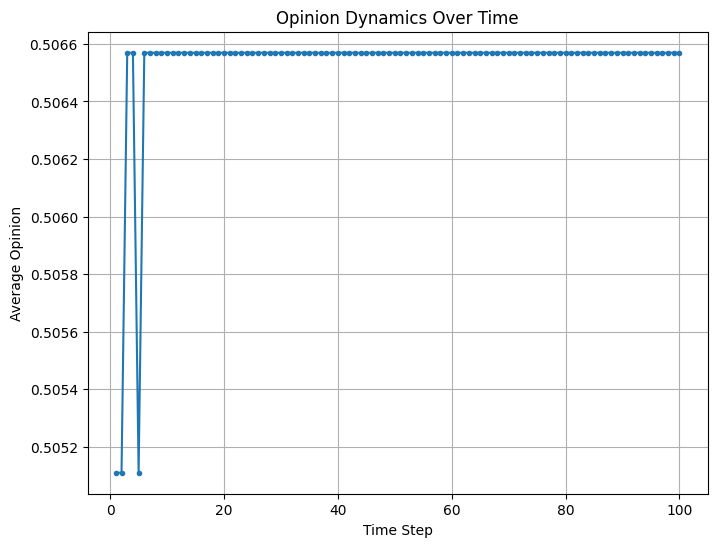

In [127]:
# Define parameters for the Voter Model
q_value = 1.5  # Nonlinearity parameter
latency_gassian = np.clip(np.random.normal(3,1,size=num_nodes), 1, None).astype(int)
consensus_threshold = 0.8  # Consensus threshold

# Test with Gassian Distribution
model = VoterModel(num_nodes, hyperedges, q=q_value, latency=latency_gassian, consensus_threshold=consensus_threshold)
history = model.run(max_steps=100)

model.plot_history()

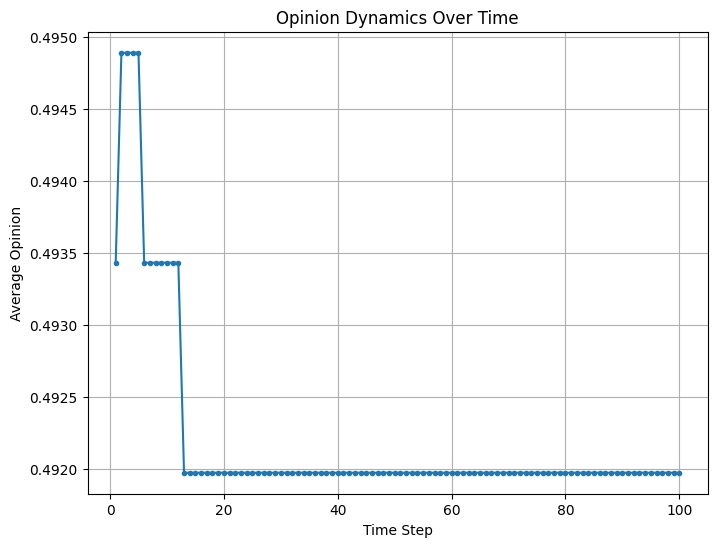

In [128]:
# Test with random latency
latency_random = np.random.randint(1, 5, size=num_nodes)  # Random latency between 1 and 4
model_random = VoterModel(num_nodes, hyperedges, q=q_value, latency=latency_random, consensus_threshold=consensus_threshold)
history_random = model_random.run(max_steps=100)

model_random.plot_history()

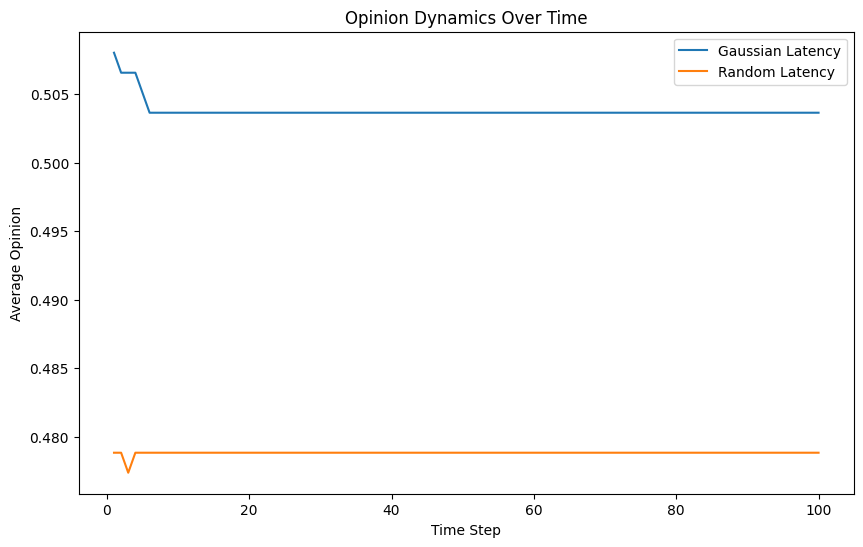

In [129]:
import random
import numpy as np
import matplotlib.pyplot as plt

# Define the Hybrid Hypergraph-Nonlinear-Latency Voter Model
class VoterModel:
    def __init__(self, num_nodes, hyperedges, q, latency, consensus_threshold):
        self.num_nodes = num_nodes
        self.hyperedges = hyperedges
        self.q = q
        self.latency = latency  # Latency periods for nodes
        self.consensus_threshold = consensus_threshold
        self.opinions = np.random.choice([0, 1], size=num_nodes)  # Random initial opinions (0 or 1)
        self.last_change_time = np.zeros(num_nodes, dtype=int)  # Time of last opinion change for nodes
        self.time_step = 0
        self.history = []
        self.consensus_time = None

    def precompute_influence_scores(self, edge):
        """Precompute influence scores for an edge."""
        s0 = sum(1 for node in edge if self.opinions[node] == 0)
        s1 = sum(1 for node in edge if self.opinions[node] == 1)
        return s0, s1

    def update_opinion(self):
        """Update the opinions of all nodes based on influence and latency."""
        new_opinions = self.opinions.copy()
        for edge in self.hyperedges:
            s0, s1 = self.precompute_influence_scores(edge)
            s0, s1 = s0 ** self.q, s1 ** self.q  # Apply nonlinearity
            for node in edge:
                if self.time_step - self.last_change_time[node] >= self.latency[node]:
                    p1 = s1 / (s0 + s1) if (s0 + s1) > 0 else 0.5
                    new_opinions[node] = 1 if random.random() < p1 else 0
                    if new_opinions[node] != self.opinions[node]:
                        self.last_change_time[node] = self.time_step
        self.opinions = new_opinions

    def check_consensus(self):
        """Check if a consensus is reached."""
        majority_opinion = np.mean(self.opinions)
        if majority_opinion >= self.consensus_threshold or majority_opinion <= 1 - self.consensus_threshold:
            self.consensus_time = self.time_step
            return True
        return False

    def run(self, max_steps=100):
        """Run the voter model for a maximum number of steps."""
        for self.time_step in range(1, max_steps + 1):
            self.history.append(np.mean(self.opinions))
            if self.check_consensus():
                print(f"Consensus reached at step {self.time_step}")
                break
            self.update_opinion()
        return self.history

    def plot_history(self, label=""):
        """Plot the history of average opinions over time."""
        plt.plot(range(1, len(self.history) + 1), self.history, label=label)
        plt.xlabel("Time Step")
        plt.ylabel("Average Opinion")
        plt.title("Opinion Dynamics Over Time")
        plt.grid()
        plt.legend()

# Preprocessing the dataset
# Map sentiment to binary opinions (1 for Positive, 0 for Negative or Neutral)
sentiment_data['Opinion'] = sentiment_data['Sentiment'].apply(lambda x: 1 if x == 'Positive' else 0)

# Extract unique users as nodes
unique_users = sentiment_data['User'].unique()
num_nodes = len(unique_users)

# Map users to node indices
user_to_node = {user: idx for idx, user in enumerate(unique_users)}
sentiment_data['Node'] = sentiment_data['User'].map(user_to_node)

# Generate hyperedges based on hashtags (users sharing the same hashtag form a hyperedge)
hashtag_groups = sentiment_data.groupby('Hashtags')['Node'].apply(list).tolist()
hyperedges = [group for group in hashtag_groups if len(group) > 1]  # Ignore single-user hyperedges

# Define parameters for the Voter Model
q_value = 1.5  # Nonlinearity parameter
latency_gaussian = np.clip(np.random.normal(3, 1, size=num_nodes), 1, None).astype(int)
latency_random = np.random.randint(1, 5, size=num_nodes)  # Random latency between 1 and 4
consensus_threshold = 0.8  # Consensus threshold

# Run simulation with Gaussian latency
model_gaussian = VoterModel(num_nodes, hyperedges, q=q_value, latency=latency_gaussian, consensus_threshold=consensus_threshold)
history_gaussian = model_gaussian.run(max_steps=100)

# Run simulation with random latency
model_random = VoterModel(num_nodes, hyperedges, q=q_value, latency=latency_random, consensus_threshold=consensus_threshold)
history_random = model_random.run(max_steps=100)

# Plot comparison of results
plt.figure(figsize=(10, 6))
model_gaussian.plot_history(label="Gaussian Latency")
model_random.plot_history(label="Random Latency")
plt.show()


### Updated Emperimental HNL Voter Model

In [134]:
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt

class HNLVoterModel:
    def __init__(self, nodes, hyperedges, influence_weights, q, latencies, consensus_threshold):
        self.nodes = nodes
        self.hyperedges = hyperedges
        self.influence_weights = influence_weights
        self.q = q
        self.latencies = latencies
        self.consensus_threshold = consensus_threshold
        self.opinions = np.random.choice([0, 1], size=len(nodes))  # Initial opinions
        self.last_change_time = np.zeros(len(nodes))  # Last opinion change time
        self.time_step = 0
        self.history = []  # Store opinion diversity, oscillations, and cascade size

    def compute_influence_scores(self, edge):
        """Compute influence scores S_0 and S_1 for a given hyperedge."""
        S_0 = sum(self.influence_weights[j] for j in edge if self.opinions[j] == 0)
        S_1 = sum(self.influence_weights[j] for j in edge if self.opinions[j] == 1)
        return S_0, S_1

    def update_opinions(self):
        """Update opinions of all nodes based on hyperedge influence."""
        new_opinions = self.opinions.copy()
        for edge in self.hyperedges:
            S_0, S_1 = self.compute_influence_scores(edge)
            S_0, S_1 = S_0 ** self.q, S_1 ** self.q
            for node in edge:
                if self.time_step - self.last_change_time[node] >= self.latencies[node]:
                    P_1 = S_1 / (S_0 + S_1) if (S_0 + S_1) > 0 else 0.5
                    new_opinions[node] = 1 if random.random() < P_1 else 0
                    if new_opinions[node] != self.opinions[node]:
                        self.last_change_time[node] = self.time_step
        self.opinions = new_opinions

    def compute_metrics(self):
        """Compute diversity, cascade size, and oscillatory behavior metrics."""
        n_0 = np.sum(self.opinions == 0)
        n_1 = np.sum(self.opinions == 1)
        diversity = 1 - max(n_0, n_1) / len(self.nodes)
        if self.time_step > 0 and len(self.history) > 0:
            cascade_size = np.sum(self.opinions != self.history[-1]["opinions"]) / len(self.nodes)
        else:
            cascade_size = 0
        oscillation = np.mean(self.opinions)
        return diversity, cascade_size, oscillation

    def check_consensus(self):
        """Check if consensus threshold is reached."""
        majority_opinion = np.mean(self.opinions)
        if majority_opinion >= self.consensus_threshold or majority_opinion <= 1 - self.consensus_threshold:
            return True
        return False

    def run_simulation(self, max_steps=100):
        """Run the simulation for a maximum number of time steps."""
        for self.time_step in range(1, max_steps + 1):
            diversity, cascade_size, oscillation = self.compute_metrics()
            self.history.append({"diversity": diversity, "cascade_size": cascade_size, "oscillation": oscillation, "opinions": self.opinions.copy()})
            if self.check_consensus():
                print(f"Consensus reached at step {self.time_step}")
                break
            self.update_opinions()

    def plot_metrics(self):
        """Plot opinion diversity, cascade size, and oscillatory behavior over time."""
        diversity = [h["diversity"] for h in self.history]
        cascade_size = [h["cascade_size"] for h in self.history]
        oscillation = [h["oscillation"] for h in self.history]

        plt.figure(figsize=(15, 5))

        plt.subplot(1, 3, 1)
        plt.plot(diversity, label="Opinion Diversity")
        plt.xlabel("Time Step")
        plt.ylabel("Diversity")
        plt.title("Opinion Diversity Over Time")
        plt.grid()
        plt.legend()

        plt.subplot(1, 3, 2)
        plt.plot(cascade_size, label="Cascade Size")
        plt.xlabel("Time Step")
        plt.ylabel("Cascade Size")
        plt.title("Cascade Size Over Time")
        plt.grid()
        plt.legend()

        plt.subplot(1, 3, 3)
        plt.plot(oscillation, label="Oscillatory Behavior")
        plt.xlabel("Time Step")
        plt.ylabel("Average Opinion")
        plt.title("Oscillatory Behavior Over Time")
        plt.grid()
        plt.legend()

        plt.tight_layout()
        plt.show()

# Load Dataset
dataset = pd.read_csv("sentimentdataset.csv")
dataset["Opinion"] = dataset["Sentiment"].apply(lambda x: 1 if x == "Positive" else 0)

# Preprocess Nodes and Hyperedges
unique_users = dataset["User"].unique()
user_to_node = {user: idx for idx, user in enumerate(unique_users)}
dataset["Node"] = dataset["User"].map(user_to_node)

# Create Hyperedges based on Hashtags
hashtag_groups = dataset.groupby("Hashtags")["Node"].apply(list).tolist()
hyperedges = [group for group in hashtag_groups if len(group) > 1]


In [136]:
print(dataset.columns)

Index(['Unnamed: 0.1', 'Unnamed: 0', 'Text', 'Sentiment', 'Timestamp', 'User',
       'Platform', 'Hashtags', 'Retweets', 'Likes', 'Country', 'Year', 'Month',
       'Day', 'Hour', 'Opinion', 'Node'],
      dtype='object')


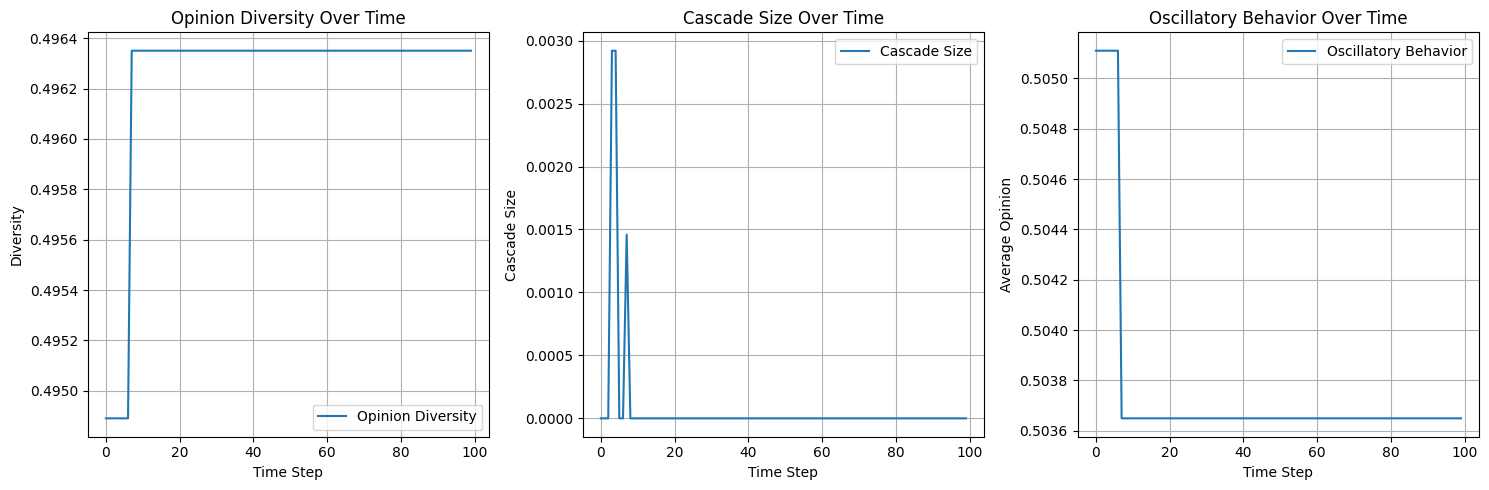

In [145]:
# Engagement Metrics
dataset['Engagement Metrics'] = dataset['Retweets'].fillna(0) + dataset['Likes'].fillna(0)

# Define Parameters
engagement_metrics = dataset.groupby("Node")["Engagement Metrics"].mean()
influence_weights = engagement_metrics.fillna(0) / engagement_metrics.max()

q = 1.5  # Nonlinearity

#  latency -> random
latencies = np.clip(np.random.normal(3, 1, size=len(unique_users)), 1, None).astype(int)
consensus_threshold = 0.8

# Run Model
model = HNLVoterModel(
    nodes=unique_users,
    hyperedges=hyperedges,
    influence_weights=influence_weights,
    q=q,
    latencies=latencies,
    consensus_threshold=consensus_threshold
)
model.run_simulation(max_steps=100)
model.plot_metrics()
